In [ ]:
import pandas as pd

df = pd.read_csv("IMDBDataset.csv")
df.head()
df.info()
df['sentiment'].value_counts()


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Text Preprocessing Strategy

In [ ]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_text(review):
    # 1. Convert to lowercase
    review = review.lower()
    
    # 2. Remove HTML tags
    review = re.sub(r'<.*?>', '', review)
    
    # 3. Remove special characters and numbers
    review = re.sub(r'[^a-zA-Z]', ' ', review)
    
    # 4. Tokenization
    words = review.split()
    
    # 5. Remove stopwords
    words = [word for word in words if word not in stop_words]
    
    # 6. Join words back into sentence
    return ' '.join(words)


[nltk_data] Downloading package stopwords to C:\Users\HARISH
[nltk_data]     NAYAK\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [8]:
df['cleaned_review'] = df['review'].apply(clean_text)
df[['review', 'cleaned_review']].head()


,review,cleaned_review
0,One of the other reviewers has mentioned that ...,one reviewers mentioned watching oz episode ho...
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,basically family little boy jake thinks zombie...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei love time money visually stunnin...


In [9]:
df['original_length'] = df['review'].apply(len)
df['cleaned_length'] = df['cleaned_review'].apply(len)

df[['original_length', 'cleaned_length']].describe()


,original_length,cleaned_length
count,50000.000000,50000.000000
mean,1309.431020,814.021020
std,989.728014,631.218449
min,32.000000,17.000000
25%,699.000000,425.000000
50%,970.000000,598.000000
75%,1590.250000,990.000000
max,13704.000000,9155.000000


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1)   # unigrams only for clarity
)
X = tfidf.fit_transform(df['cleaned_review'])
y = df['sentiment'].map({
    'positive': 1,
    'negative': 0
})


In [11]:
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)
feature_names = tfidf.get_feature_names_out()
print(feature_names[:20])


Feature Matrix Shape: (50000, 5000)
Target Shape: (50000,)
['aaron' 'abandoned' 'abc' 'abilities' 'ability' 'able' 'absence' 'absent'
 'absolute' 'absolutely' 'absurd' 'abuse' 'abused' 'abusive' 'abysmal'
 'academy' 'accent' 'accents' 'accept' 'acceptable']


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
model = LogisticRegression(
    max_iter=1000
)
model.fit(X_train, y_train)
print("Training completed successfully")


Training completed successfully


In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print(classification_report(y_test, y_pred))


Model Accuracy: 89.31 %
              precision    recall  f1-score   support

           0       0.90      0.88      0.89      5000
           1       0.89      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [14]:
cm = confusion_matrix(y_test, y_pred)
cm


array([[4423,  577],
       [ 492, 4508]])

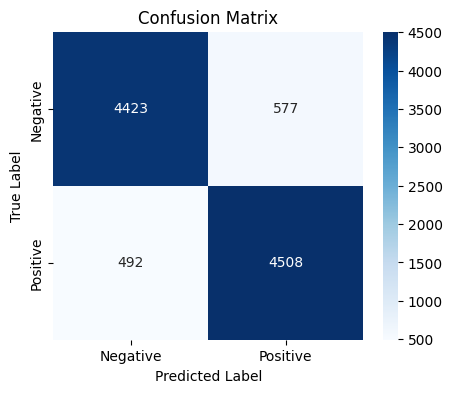

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


In [16]:
y_proba = model.predict_proba(X_test)


In [17]:
sample_index = 0

sample_probs = y_proba[sample_index]
sample_prediction = y_pred[sample_index]

confidence = max(sample_probs) * 100

print("Predicted Label:", "Positive" if sample_prediction == 1 else "Negative")
print("Confidence:", round(confidence, 2), "%")


Predicted Label: Negative
Confidence: 66.2 %


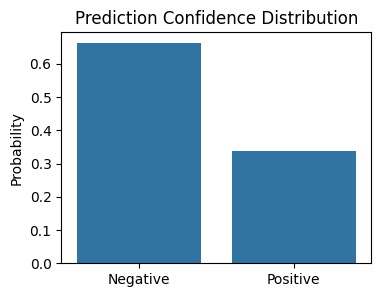

In [18]:
labels = ['Negative', 'Positive']

plt.figure(figsize=(4,3))
sns.barplot(x=labels, y=sample_probs)
plt.title("Prediction Confidence Distribution")
plt.ylabel("Probability")
plt.show()


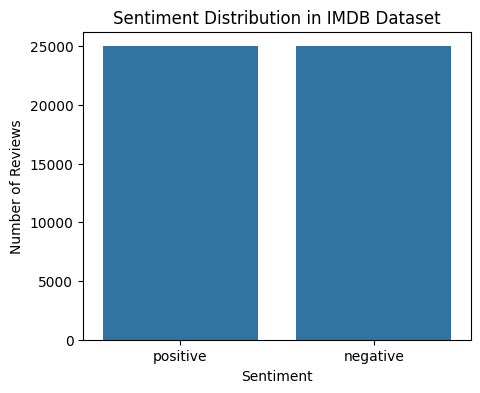

In [19]:
plt.figure(figsize=(5,4))
sns.countplot(x=df['sentiment'])
plt.title("Sentiment Distribution in IMDB Dataset")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


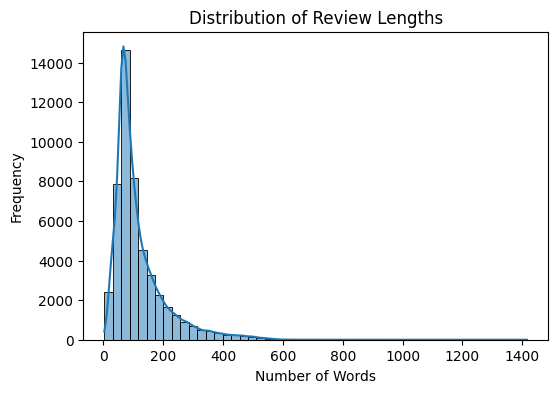

In [20]:
df['review_length'] = df['cleaned_review'].apply(lambda x: len(x.split()))

plt.figure(figsize=(6,4))
sns.histplot(df['review_length'], bins=50, kde=True)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()


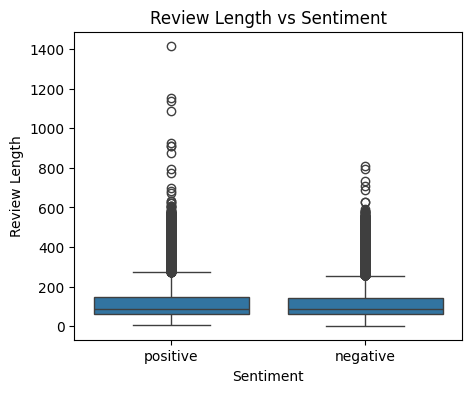

In [21]:
plt.figure(figsize=(5,4))
sns.boxplot(x='sentiment', y='review_length', data=df)
plt.title("Review Length vs Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Review Length")
plt.show()


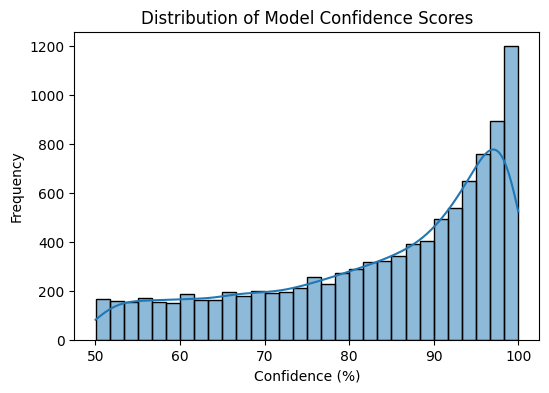

In [22]:
confidence_scores = y_proba.max(axis=1) * 100

plt.figure(figsize=(6,4))
sns.histplot(confidence_scores, bins=30, kde=True)
plt.title("Distribution of Model Confidence Scores")
plt.xlabel("Confidence (%)")
plt.ylabel("Frequency")
plt.show()


In [23]:
low_conf_indices = confidence_scores.argsort()[:5]
high_conf_indices = confidence_scores.argsort()[-5:]

print("Low confidence examples:")
for i in low_conf_indices:
    print(confidence_scores[i])

print("\nHigh confidence examples:")
for i in high_conf_indices:
    print(confidence_scores[i])


Low confidence examples:
50.01346683821472
50.01636307277983
50.01655878331888
50.025512093773294
50.02904112872441

High confidence examples:
99.98891080456731
99.98971544148664
99.99024606970636
99.99371718853433
99.99730051204341


In [24]:
def predict_sentiment(text):
    """
    Predicts sentiment and confidence score for a given text.
    """
    # Step 1: Clean text
    cleaned_text = clean_text(text)
    
    # Step 2: Vectorize text
    vectorized_text = tfidf.transform([cleaned_text])
    
    # Step 3: Predict sentiment
    prediction = model.predict(vectorized_text)[0]
    
    # Step 4: Get confidence score
    probabilities = model.predict_proba(vectorized_text)[0]
    confidence = max(probabilities) * 100
    
    # Step 5: Format output
    sentiment = "Positive" if prediction == 1 else "Negative"
    
    return sentiment, round(confidence, 2)


In [25]:
sample_reviews = [
    "This movie was absolutely fantastic, I loved every moment!",
    "The plot was boring and the acting was terrible.",
    "It was okay, not great but not bad either."
]

for review in sample_reviews:
    sentiment, confidence = predict_sentiment(review)
    print(f"Review: {review}")
    print(f"Prediction: {sentiment} ({confidence}% confident)")
    print("-" * 60)


Review: This movie was absolutely fantastic, I loved every moment!
Prediction: Positive (96.92% confident)
------------------------------------------------------------
Review: The plot was boring and the acting was terrible.
Prediction: Negative (99.98% confident)
------------------------------------------------------------
Review: It was okay, not great but not bad either.
Prediction: Negative (94.63% confident)
------------------------------------------------------------


In [26]:
def visualize_prediction(text):
    cleaned = clean_text(text)
    vec = tfidf.transform([cleaned])
    probs = model.predict_proba(vec)[0]

    plt.figure(figsize=(4,3))
    sns.barplot(x=['Negative', 'Positive'], y=probs)
    plt.title("Sentiment Confidence")
    plt.ylabel("Probability")
    plt.show()


In [27]:
import pickle
with open("sentiment_model.pkl", "wb") as model_file:
    pickle.dump(model, model_file)
print("Model and TF-IDF vectorizer saved successfully!")


Model and TF-IDF vectorizer saved successfully!


In [28]:
with open("sentiment_model.pkl", "rb") as model_file:
    loaded_model = pickle.load(model_file)




In [29]:
import pickle

with open("tfidf_vectorizer.pkl", "wb") as vectorizer_file:
    pickle.dump(tfidf, vectorizer_file)

print("TF-IDF vectorizer saved successfully!")


TF-IDF vectorizer saved successfully!


In [30]:
with open("tfidf_vectorizer.pkl", "rb") as vectorizer_file:
    loaded_tfidf = pickle.load(vectorizer_file)

print("Vectorizer loaded successfully!")


Vectorizer loaded successfully!


In [31]:
def predict_with_loaded_model(text):
    """
    Predicts sentiment using the loaded model and vectorizer.
    """
    cleaned_text = clean_text(text)
    vectorized_text = loaded_tfidf.transform([cleaned_text])
    prediction = loaded_model.predict(vectorized_text)[0]
    probabilities = loaded_model.predict_proba(vectorized_text)[0]
    confidence = max(probabilities) * 100
    sentiment = "Positive" if prediction == 1 else "Negative"
    return sentiment, round(confidence, 2)

sentiment, confidence = predict_with_loaded_model(
    "The movie was visually stunning and emotionally powerful"
)

print(sentiment, confidence)


Positive 90.65
